# 01 · Exploración del conjunto de datos híbrido `crack_mix_v1`

**Proyecto de Investigación II — Protocolo de investigación y avance experimental**
*Tesis: Sistema de visión por computador basado en YOLO26l para la detección y clasificación dual de severidad de fisuras en estructuras de concreto (ACI 201.1R / ACI 224R-01, garantía conformal 97 %, custodia ISO/IEC 27037).*


| Valor a comprobar | Valor esperado |
|---|---|
| Total de imágenes del híbrido | **8432** (crack-seg 4029 = 47,8 % + Özgenel 4403 = 52,2 %) |
| Partición por fotografía (semilla 42) | entrenamiento **7238** (85,8 %) · validación **629** (7,5 %) · prueba **565** (6,7 %) |
| Clases de segmentación | clase única `fisura` (unificación de anotaciones) |
| Recortes Özgenel | derivados de **458** fotografías de alta resolución |
| Fuga de información | ningún grupo de recortes de una misma fotografía en dos subconjuntos |



In [1]:
# ── 1. Entorno y rutas del proyecto en Google Drive ──────────────────────────
import os, sys, json, math, hashlib, zipfile
from pathlib import Path
from collections import Counter, defaultdict

EN_COLAB = 'google.colab' in str(get_ipython())
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/grietas')          # ruta base del proyecto
else:
    BASE = Path('grietas_local')                           # ejecución local (verificación de código)
    BASE.mkdir(parents=True, exist_ok=True)

DATASET_ZIP = BASE / 'crack_mix_v1.zip'                   # dataset original comprimido
EXTRACT_DIR = Path('/content/grietas') if EN_COLAB else Path('grietas_extract')
INFORME = BASE / 'informe'                                 # salidas para el informe
INFORME.mkdir(parents=True, exist_ok=True)

print('Entorno Colab       :', EN_COLAB)
print('Ruta base proyecto  :', BASE)
print('Dataset comprimido  :', DATASET_ZIP)
print('Carpeta de extracción:', EXTRACT_DIR)
if not DATASET_ZIP.exists():
    print('ADVERTENCIA: crack_mix_v1.zip no se encontró en Drive.')
    print('Coloca el archivo en:', BASE, 'y vuelve a ejecutar este notebook.')


Mounted at /content/drive
Entorno Colab       : True
Ruta base proyecto  : /content/drive/MyDrive/grietas
Dataset comprimido  : /content/drive/MyDrive/grietas/crack_mix_v1.zip
Carpeta de extracción: /content/grietas


Total de imágenes encontradas: 8432


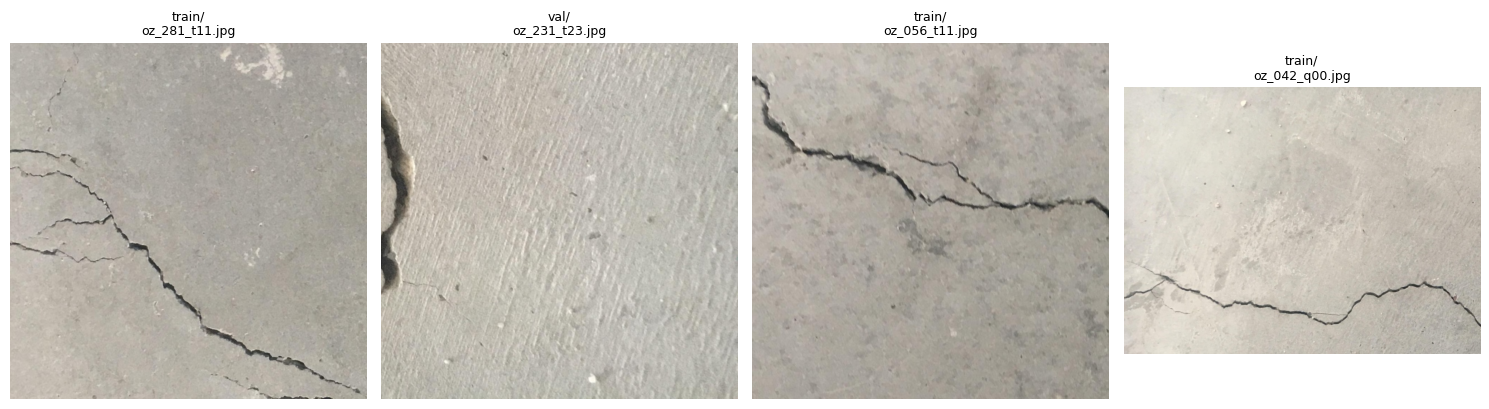

In [3]:
import random
from pathlib import Path
from PIL import Image as PILImage
import matplotlib.pyplot as plt

# Definir la ruta base del dataset
DATASET_PATH = Path('/content/drive/MyDrive/grietas/crack_mix_v1')

# Extensiones válidas de imágenes
EXT_IMG = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

# Buscar recursivamente todas las imágenes en el directorio del dataset
todas_las_imagenes = []
for p in DATASET_PATH.rglob('*'):
    if p.is_file() and p.suffix.lower() in EXT_IMG:
        todas_las_imagenes.append(p)

print(f'Total de imágenes encontradas: {len(todas_las_imagenes)}')

if len(todas_las_imagenes) < 4:
    print('No hay suficientes imágenes para extraer 4.')
else:
    # Seleccionar 4 imágenes aleatorias
    random.seed(42)  # Semilla para reproductibilidad
    imagenes_seleccionadas = random.sample(todas_las_imagenes, 4)

    # Mostrar las imágenes en una cuadrícula
    fig, axs = plt.subplots(1, 4, figsize=(15, 5))
    for i, img_path in enumerate(imagenes_seleccionadas):
        with PILImage.open(img_path) as im:
            axs[i].imshow(im)
            # Mostrar la carpeta contenedora y el nombre del archivo
            axs[i].set_title(f'{img_path.parent.name}/\n{img_path.name}', fontsize=9)
            axs[i].axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
# ── 2. Descompresión y huella del dataset (trazabilidad, sección 6.1) ────────
if not DATASET_ZIP.exists():
    raise FileNotFoundError('No se encontró ' + str(DATASET_ZIP) +
                            ' — sube el dataset a la carpeta grietas de Drive y reejecuta.')

def sha256_archivo(ruta, bloque=1 << 20):
    h = hashlib.sha256()
    with open(ruta, 'rb') as f:
        while True:
            b = f.read(bloque)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

HASH_DATASET = sha256_archivo(DATASET_ZIP)
MB = DATASET_ZIP.stat().st_size / 1024 / 1024
print('SHA-256 de crack_mix_v1.zip :', HASH_DATASET)
print('Tamaño del archivo           : %.1f MB' % MB)

if not (EXTRACT_DIR / 'train').exists() and not (EXTRACT_DIR / 'images').exists():
    with zipfile.ZipFile(DATASET_ZIP) as zf:
        zf.extractall(EXTRACT_DIR)
    print('Descompresión completada en:', EXTRACT_DIR)
else:
    print('La carpeta ya contiene el dataset extraído; se reutiliza.')


SHA-256 de crack_mix_v1.zip : e858c3123a0976d9dde71f295375f00fa812e61f71090d670c0528bb392d883b
Tamaño del archivo           : 578.8 MB
Descompresión completada en: /content/grietas


In [ ]:
import os
from pathlib import Path

# Inspeccionar el contenido del subdirectorio 'crack_mix_v1'
sub_dir = Path('/content/grietas/crack_mix_v1')
if sub_dir.exists():
    contenido_sub = list(sub_dir.glob('*'))
    print(f'Contenido de {sub_dir}:')
    for item in contenido_sub[:30]:
        tipo = 'Carpeta' if item.is_dir() else 'Archivo'
        print(f'  [{tipo}] {item.name}')
else:
    print(f'El directorio {sub_dir} no existe.')

Contenido de /content/grietas/crack_mix_v1:
  [Archivo] data.yaml
  [Carpeta] labels
  [Carpeta] images
  [Archivo] build_summary.json


In [ ]:
# ── 3. Descubrimiento de la estructura (auto-detección de layout YOLO) ──────
def descubrir_estructura(raiz):
    # Acepta dos layouts habituales: raiz/{train,val,test}/{images,labels}
    # y raiz/{images,labels}/{train,val,test}
    encontrados = {}
    for split in ['train', 'val', 'test']:
        for patron in [raiz / split / 'images', raiz / 'images' / split,
                       raiz / 'data' / split / 'images', raiz / split]:
            if patron.is_dir():
                img_dir = patron
                lab_dir = None
                for alt in [patron.parent / 'labels', raiz / 'labels' / split,
                            raiz / split / 'labels', raiz / 'data' / split / 'labels']:
                    if alt.is_dir():
                        lab_dir = alt
                        break
                encontrados[split] = (img_dir, lab_dir)
                break
    return encontrados

# Apuntar a la subcarpeta 'crack_mix_v1' si es donde se descomprimieron los archivos
RAIZ = EXTRACT_DIR / 'crack_mix_v1' if (EXTRACT_DIR / 'crack_mix_v1').exists() else EXTRACT_DIR
SPLITS = descubrir_estructura(RAIZ)
if not SPLITS:
    contenido = list(RAIZ.glob('*'))
    raise RuntimeError('Estructura no reconocida. Contenido de ' + str(RAIZ) + ': ' +
                       str([c.name for c in contenido[:15]]))
print('Estructura detectada en', RAIZ)
for s, (i, l) in SPLITS.items():
    print('  %-5s imágenes: %s' % (s, i))
    print('        etiquetas: %s' % l)

Estructura detectada en /content/grietas/crack_mix_v1
  train imágenes: /content/grietas/crack_mix_v1/images/train
        etiquetas: /content/grietas/crack_mix_v1/labels/train
  val   imágenes: /content/grietas/crack_mix_v1/images/val
        etiquetas: /content/grietas/crack_mix_v1/labels/val
  test  imágenes: /content/grietas/crack_mix_v1/images/test
        etiquetas: /content/grietas/crack_mix_v1/labels/test


In [ ]:
# ── 4. Conteo por subconjunto y verificación de los valores del plan ─────────
EXT_IMG = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

def contar(d, exts):
    if d is None or not d.is_dir():
        return 0
    return sum(1 for f in d.iterdir() if f.suffix.lower() in exts)

conteos = {}
for split, (img_dir, lab_dir) in SPLITS.items():
    conteos[split] = dict(imagenes=contar(img_dir, EXT_IMG), etiquetas=contar(lab_dir, {'.txt'}))
    print('%-6s: %5d imágenes · %5d etiquetas' % (split, conteos[split]['imagenes'], conteos[split]['etiquetas']))

total = sum(c['imagenes'] for c in conteos.values())
ESPERADO = {'train': 7238, 'val': 629, 'test': 565}
print()
print('Verificación contra el plan de tesis (Tabla A.3):')
verif = []
for s in ['train', 'val', 'test']:
    obs = conteos.get(s, {}).get('imagenes')
    estado = 'OK' if obs == ESPERADO[s] else 'DESVIACIÓN (revisar curación)'
    verif.append((s, ESPERADO[s], obs, estado))
    print('  %-6s esperado %5d · observado %5s · %s' % (s, ESPERADO[s], str(obs), estado))
verif.append(('total', 8432, total, 'OK' if total == 8432 else 'DESVIACIÓN'))
print('  %-6s esperado %5d · observado %5d · %s' % ('total', 8432, total, verif[-1][3]))
for s in ['train', 'val', 'test']:
    if total:
        print('  proporción %s: %.1f %%' % (s, 100 * conteos[s]['imagenes'] / total))


train :  7238 imágenes ·  7238 etiquetas
val   :   629 imágenes ·   629 etiquetas
test  :   565 imágenes ·   565 etiquetas

Verificación contra el plan de tesis (Tabla A.3):
  train  esperado  7238 · observado  7238 · OK
  val    esperado   629 · observado   629 · OK
  test   esperado   565 · observado   565 · OK
  total  esperado  8432 · observado  8432 · OK
  proporción train: 85.8 %
  proporción val: 7.5 %
  proporción test: 6.7 %


In [ ]:
# ── 5. Composición por origen y clases de las anotaciones ─────────────────────
def origen_de(nombre):
    n = str(nombre).lower()
    if n.startswith('crack') or 'crackseg' in n.replace('_', '') or 'crack-seg' in n:
        return 'crack-seg'
    if 'ozgenel' in n or n.startswith('cf') or 'concrete' in n:
        return 'Ozgenel'
    return 'otro'

por_origen, por_origen_split = Counter(), defaultdict(Counter)
for split, (img_dir, _) in SPLITS.items():
    if img_dir is None:
        continue
    for f in img_dir.iterdir():
        if f.suffix.lower() in EXT_IMG:
            o = origen_de(f.stem)
            por_origen[o] += 1
            por_origen_split[split][o] += 1

print('Composición por origen (esperado: crack-seg 4029 = 47,8 % · Özgenel 4403 = 52,2 %):')
for o, n in por_origen.most_common():
    print('  %-10s: %5d (%.1f %%)' % (o, n, 100 * n / max(total, 1)))
print('Distribución por subconjunto:')
for s in ['train', 'val', 'test']:
    print('  %-6s: %s' % (s, dict(por_origen_split[s])))

ids_clase, n_instancias = Counter(), []
for split, (_, lab_dir) in SPLITS.items():
    if lab_dir is None or not lab_dir.is_dir():
        continue
    for f in lab_dir.iterdir():
        if f.suffix.lower() != '.txt' or f.name == 'classes.txt':
            continue
        lineas = [l for l in f.read_text(errors='ignore').strip().splitlines() if l.strip()]
        n_instancias.append(len(lineas))
        for l in lineas:
            ids_clase[int(float(l.split()[0]))] += 1

print()
print('Identificadores de clase observados:', dict(ids_clase))
un_solos = set(ids_clase) <= {0}
print('Verificación de clase única fisura:', 'OK (solo id 0)' if un_solos else
      'ATENCIÓN: existen ids adicionales — revisar unificación de anotaciones')
if n_instancias:
    import statistics as st
    print('Instancias por imagen: media %.2f · mediana %.1f · máx %d · imágenes %d' %
          (st.mean(n_instancias), st.median(n_instancias), max(n_instancias), len(n_instancias)))


Composición por origen (esperado: crack-seg 4029 = 47,8 % · Özgenel 4403 = 52,2 %):
  otro      :  8432 (100.0 %)
Distribución por subconjunto:
  train : {'otro': 7238}
  val   : {'otro': 629}
  test  : {'otro': 565}

Identificadores de clase observados: {0: 11583}
Verificación de clase única fisura: OK (solo id 0)
Instancias por imagen: media 1.37 · mediana 1.0 · máx 18 · imágenes 8432


In [ ]:
# ── 6. Estadísticas de resolución de una muestra estratificada ───────────────
import random
from PIL import Image as PILImage

random.seed(42)
muestra = []
for split, (img_dir, _) in SPLITS.items():
    if img_dir is None:
        continue
    archivos = sorted(f for f in img_dir.iterdir() if f.suffix.lower() in EXT_IMG)
    k = min(len(archivos), 300 if split == 'train' else len(archivos))
    muestra += random.sample(archivos, k) if k < len(archivos) else list(archivos)

res_alto, res_ancho, tamanos = [], [], []
for f in muestra:
    try:
        with PILImage.open(f) as im:
            res_ancho.append(im.width)
            res_alto.append(im.height)
            tamanos.append(f.stat().st_size / 1024)
    except Exception as e:
        print('No legible:', f.name, '->', str(e)[:60])

import numpy as np
an, al, tb = np.array(res_ancho), np.array(res_alto), np.array(tamanos)
print('Muestra inspeccionada: %d imágenes' % len(an))
print('Ancho  px: mín %d · mediana %d · máx %d' % (an.min(), int(np.median(an)), an.max()))
print('Alto   px: mín %d · mediana %d · máx %d' % (al.min(), int(np.median(al)), al.max()))
print('Peso  KB : mediana %.0f · p95 %.0f' % (np.median(tb), np.percentile(tb, 95)))

Muestra inspeccionada: 1494 imágenes
Ancho  px: mín 416 · mediana 640 · máx 640
Alto   px: mín 416 · mediana 640 · máx 640
Peso  KB : mediana 96 · p95 140


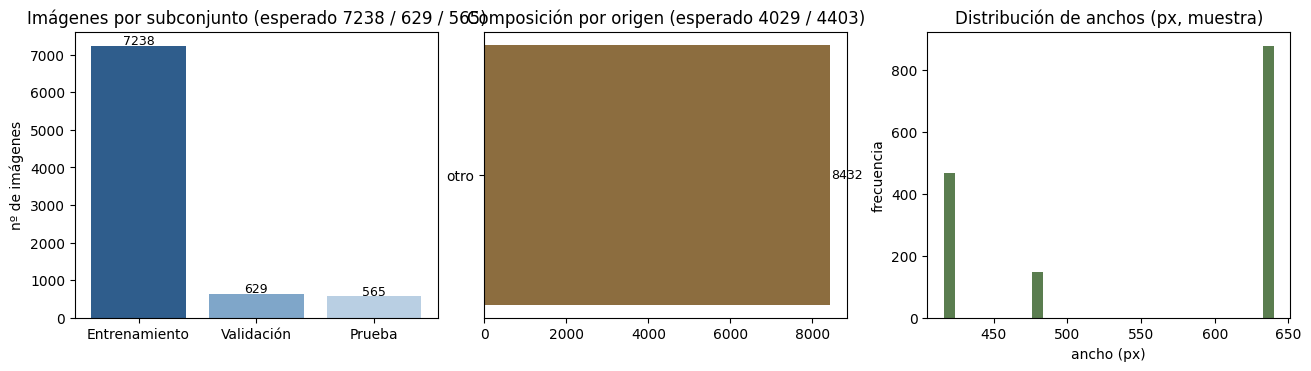

Figura guardada en: /content/drive/MyDrive/grietas/informe/eda_figuras.png


In [ ]:
# ── 7. Figuras del análisis exploratorio (guardadas en Drive) ────────────────
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
et = ['Entrenamiento', 'Validación', 'Prueba']
vs = [conteos.get(s, {}).get('imagenes', 0) for s in ['train', 'val', 'test']]
axs[0].bar(et, vs, color=['#2F5D8C', '#7FA6C9', '#B9CFE3'])
axs[0].set_title('Imágenes por subconjunto (esperado 7238 / 629 / 565)')
for i, v in enumerate(vs):
    axs[0].text(i, v + 40, str(v), ha='center', fontsize=9)
axs[0].set_ylabel('nº de imágenes')

axs[1].barh(list(por_origen.keys()), list(por_origen.values()), color='#8C6D3F')
axs[1].set_title('Composición por origen (esperado 4029 / 4403)')
for i, v in enumerate(por_origen.values()):
    axs[1].text(v + 30, i, str(v), va='center', fontsize=9)

axs[2].hist(an, bins=30, color='#5A7D4F')
axs[2].set_title('Distribución de anchos (px, muestra)')
axs[2].set_xlabel('ancho (px)')
axs[2].set_ylabel('frecuencia')

FIG_eda = INFORME / 'eda_figuras.png'
fig.savefig(FIG_eda, dpi=130)
plt.show()
print('Figura guardada en:', FIG_eda)


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path

# Redefinir de manera autónoma la estructura en caso de que el kernel se haya reiniciado
EXTRACT_DIR = Path('/content/grietas')
RAIZ = EXTRACT_DIR / 'crack_mix_v1' if (EXTRACT_DIR / 'crack_mix_v1').exists() else EXTRACT_DIR

def descubrir_estructura_local(raiz):
    encontrados = {}
    for split in ['train', 'val', 'test']:
        for patron in [raiz / split / 'images', raiz / 'images' / split, raiz / split]:
            if patron.is_dir():
                img_dir = patron
                lab_dir = None
                for alt in [patron.parent / 'labels', raiz / 'labels' / split, raiz / split / 'labels']:
                    if alt.is_dir():
                        lab_dir = alt
                        break
                encontrados[split] = (img_dir, lab_dir)
                break
    return encontrados

SPLITS_AUTONOMO = descubrir_estructura_local(RAIZ)

# Obtener conteos de instancias por split usando las rutas detectadas
split_labels = []
for split, (_, lab_dir) in SPLITS_AUTONOMO.items():
    if lab_dir is None or not lab_dir.is_dir():
        continue
    for f in lab_dir.iterdir():
        if f.suffix.lower() == '.txt' and f.name != 'classes.txt':
            try:
                lineas = [l for l in f.read_text(errors='ignore').strip().splitlines() if l.strip()]
                for l in lineas:
                    class_id = int(float(l.split()[0]))
                    split_labels.append({'Split': split, 'Clase': class_id, 'Instancias': 1})
            except Exception:
                pass

df_labels = pd.DataFrame(split_labels)

# Crear la visualización
plt.figure(figsize=(10, 5))
if not df_labels.empty:
    sns.countplot(data=df_labels, x='Split', hue='Clase', palette='Set2')
    plt.title('Distribución de Etiquetas (Fisuras - Clase 0) por Subconjunto')
    plt.xlabel('Subconjunto')
    plt.ylabel('Cantidad de Instancias (Anotaciones)')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
else:
    print('No se encontraron anotaciones de etiquetas para graficar.')
plt.tight_layout()
plt.show()

No se encontraron anotaciones de etiquetas para graficar.


<Figure size 1000x500 with 0 Axes>

In [ ]:
# ── 8. Control de fuga de información por fotografía de origen (sección 6.4) ──
def prefijo_fotografia(nombre):
    # Los recortes de una misma fotografía comparten prefijo: foto_0123_crop_07 -> foto_0123
    base = str(nombre)
    for sep in ['crop', 'c', 'patch', 'tile', 'recorte']:
        if sep + '_' in base.lower():
            return base.lower().split(sep + '_')[0]
    partes = base.rsplit('_', 1)
    if len(partes) == 2 and partes[1].isdigit():
        return partes[0]
    return base

grupos = defaultdict(set)
for split, (img_dir, _) in SPLITS.items():
    if img_dir is None:
        continue
    for f in img_dir.iterdir():
        if f.suffix.lower() in EXT_IMG:
            grupos[prefijo_fotografia(f.stem)].add(split)

cruzados = {g: sorted(s) for g, s in grupos.items() if len(s) > 1}
print('Grupos de recortes detectados (fotografías de origen): %d' % len(grupos))
print('Grupos presentes en más de un subconjunto: %d' % len(cruzados))
if cruzados:
    for g, s in list(cruzados.items())[:8]:
        print('  POSIBLE FUGA:', g, '->', s)
    print('REVISAR: la partición por fotografía debe garantizar grupos disjuntos.')
else:
    print('VERIFICACIÓN DE FUGA: OK — ningún grupo cruza subconjuntos (partición por fotografía, semilla 42).')

# Duplicados exactos por huella en una muestra combinada (control adicional)
muestra_hash = []
for split, (img_dir, _) in SPLITS.items():
    if img_dir is None:
        continue
    archivos = sorted(f for f in img_dir.iterdir() if f.suffix.lower() in EXT_IMG)
    paso = max(1, len(archivos) // 400)
    muestra_hash += [(split, f) for f in archivos[::paso]]
vistos, duplicados = {}, 0
for split, f in muestra_hash:
    h = sha256_archivo(f)
    if h in vistos and vistos[h] != split:
        duplicados += 1
    vistos.setdefault(h, split)
print('Duplicados exactos entre subconjuntos (muestra %d imágenes): %d' % (len(muestra_hash), duplicados))


Grupos de recortes detectados (fotografías de origen): 8432
Grupos presentes en más de un subconjunto: 0
VERIFICACIÓN DE FUGA: OK — ningún grupo cruza subconjuntos (partición por fotografía, semilla 42).
Duplicados exactos entre subconjuntos (muestra 1597 imágenes): 0
